**Principie Cyubahiro**
---
**BSE - African Leadership University**

**Machine Learning Techniques II**

**Formative 2 - Hidden Markov Models**

## 1. Assignment Overview
I recorded my own phone motion data for four activities: **Standing, Walking, Jumping and Still**. The goal is to recover the hidden activity from noisy accelerometer and gyroscope signals with a Hidden Markov Model built from scratch in NumPy.

Pipeline: extract recordings, harmonize sampling rates, clean, window, extract time and frequency features, train the HMM with Baum-Welch, decode with Viterbi, and test on recordings the model never saw.

## 2. Background
Wearables and smart home sensors stream motion data all day, but they never receive the label "walking" or "standing". The activity is hidden; only the signal is observed. An HMM fits this setting well because:
* each activity produces a typical signal pattern (emission probabilities),
* activities last for a while and change in a sensible order (transition probabilities).

My use case: a low-cost phone-based activity monitor for elderly or recovering patients in Rwanda, where dedicated wearables are expensive but smartphones are common. Knowing when someone is still for too long, or suddenly very active, supports care at home.

## 3. Environment Setup
Libraries only for data handling and plotting. The HMM itself (forward, backward, Baum-Welch, Viterbi) is written with NumPy. In Colab the cell mounts Google Drive and reads `My Drive/Formative2_Data`.

In [1]:
import os, io, glob, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive"
except ImportError:
    BASE = "."

DATA_DIR = os.path.join(BASE, "Formative2_Data")         # 8 activity ZIP files
EXTRACT_DIR = os.path.join(BASE, "Formative2_Extracted")  # unzipped raw recordings
CLEAN_DIR = os.path.join(BASE, "Formative2_Clean")        # labelled CSV dataset
FIG_DIR = os.path.join(BASE, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

ACTIVITIES = ["Standing", "Walking", "Jumping", "Still"]
COLORS = {"Standing": "#1f77b4", "Walking": "#2ca02c", "Jumping": "#d62728", "Still": "#7f7f7f"}
TARGET_FS = 50        # harmonized sampling rate (Hz)
TRIM_S = 0.25         # seconds cut at each end (button tap, approximate time I was taking)
MAX_S = 10.0          # keep each file within 5 to 10 s
print(sorted(os.listdir(DATA_DIR)))

Mounted at /content/drive
['Jumping(100).zip', 'Jumping(50).zip', 'Standing(100).zip', 'Standing(50).zip', 'Still(100).zip', 'Still(50).zip', 'Walking(100).zip', 'Walking(50).zip']


## 4. Data Collection and Extraction
Recorded with **Sensor Logger** on an **iPhone 14 Pro**, in two sessions: one at 50 Hz and one at 100 Hz. Drive holds one ZIP per activity and rate, e.g. `Jumping(50).zip`. Inside each is one ZIP per recording, named by its start time, holding `Accelerometer.csv`, `Gyroscope.csv`, `Gravity.csv` and others.

The cell below unzips both levels into `Formative2_Extracted/<Folder>/<recording>/`. macOS `__MACOSX` files are skipped.

In [2]:
def extract_all(data_dir, out_dir):
    for outer in sorted(glob.glob(os.path.join(data_dir, "*.zip"))):
        with zipfile.ZipFile(outer) as zf:
            for name in zf.namelist():
                if "__MACOSX" in name or not name.endswith(".zip"):
                    continue
                folder, rec = name.split("/")[-2], os.path.basename(name)[:-4]
                target = os.path.join(out_dir, folder, rec)
                if not os.path.isdir(target):
                    zipfile.ZipFile(io.BytesIO(zf.read(name))).extractall(target)

extract_all(DATA_DIR, EXTRACT_DIR)
rec_dirs = sorted(glob.glob(os.path.join(EXTRACT_DIR, "*", "*")))
print(len(rec_dirs), "recordings extracted")
print(sorted(os.listdir(rec_dirs[0])))

50 recordings extracted
['Accelerometer.csv', 'AccelerometerUncalibrated.csv', 'Annotation.csv', 'Gravity.csv', 'Gyroscope.csv', 'GyroscopeUncalibrated.csv', 'Metadata.csv', 'Orientation.csv']


## 5. Loading and Sampling Rate Check
Sensor Logger splits the accelerometer into **body motion** (`Accelerometer.csv`, gravity removed) and **gravity** (`Gravity.csv`). I keep both plus the gyroscope. The true rate is measured from the nanosecond `time` column instead of trusting the folder name.

In [3]:
AXES = ["x", "y", "z"]

def read_sensor(path, name, prefix):
    df = pd.read_csv(os.path.join(path, f"{name}.csv"))
    return df["time"].values, df[AXES].values, prefix

def load_recording(path):
    t, acc, _ = read_sensor(path, "Accelerometer", "acc")
    tg, gyr, _ = read_sensor(path, "Gyroscope", "gyr")
    tv, grav, _ = read_sensor(path, "Gravity", "grav")
    sec = (t - t[0]) / 1e9
    # align gyroscope and gravity to accelerometer timestamps
    gyr = np.column_stack([np.interp(t, tg, gyr[:, i]) for i in range(3)])
    grav = np.column_stack([np.interp(t, tv, grav[:, i]) for i in range(3)])
    fs = 1.0 / np.median(np.diff(sec))
    return t, sec, np.hstack([acc, gyr, grav]), fs

SIG_COLS = [f"{s}_{a}" for s in ["acc", "gyr", "grav"] for a in AXES]
meta = []
for d in rec_dirs:
    folder = os.path.basename(os.path.dirname(d))
    t, sec, X, fs = load_recording(d)
    meta.append({"recording": os.path.basename(d), "folder": folder,
                 "activity": folder.split("(")[0], "folder_rate": int(folder.split("(")[1][:-1]),
                 "measured_fs": round(fs), "samples": len(sec), "duration_s": sec[-1],
                 "max_gap_ms": np.diff(sec).max() * 1000, "path": d})
meta = pd.DataFrame(meta)
print(meta.groupby(["folder"])[["folder_rate", "measured_fs"]].agg(lambda s: sorted(set(s))))
print("Largest timestamp gap in any file: %.1f ms" % meta.max_gap_ms.max())

              folder_rate measured_fs
folder                               
Jumping(100)        [100]       [100]
Jumping(50)          [50]   [50, 100]
Standing(100)       [100]        [50]
Standing(50)         [50]       [100]
Still(100)          [100]       [100]
Still(50)            [50]        [50]
Walking(100)        [100]       [100]
Walking(50)          [50]        [50]
Largest timestamp gap in any file: 20.0 ms


**Interpretation.** Six folders match their label. The two Standing folders are swapped: `Standing(50)` was really recorded at 100 Hz and `Standing(100)` at 50 Hz. Measuring the rate from timestamps catches this, so every file gets its true rate. The largest gap between two samples is 20 ms, exactly one sample at 50 Hz, so no file has dropouts. *[There a was a mistake in naming the folders, which is not a really issue]*

## 6. Harmonizing, Cleaning and Building One Table
Steps for every recording:
1. **Anti-alias**: 100 Hz files pass a 4th order Butterworth low-pass at 20 Hz, so nothing above the new Nyquist (25 Hz) folds back.
2. **Resample** every file onto one uniform 50 Hz grid by linear interpolation. This also removes small timing jitter.
3. **Trim** 0.25 s at both ends (tapping start and stop) and cap at 10 s.

50 Hz is chosen because it is the lower of the two rates: down-sampling loses nothing important (human motion sits below 20 Hz), while up-sampling would invent data. All recordings then go into **one table** with activity and rate columns, and each is saved as a labelled CSV with a timestamp column.

In [4]:
def harmonize(t_ns, sec, X, fs):
    if fs > TARGET_FS * 1.2:
        b, a = butter(4, 20 / (fs / 2), btype="low")
        X = filtfilt(b, a, X, axis=0)
    end = min(sec[-1] - TRIM_S, TRIM_S + MAX_S)
    grid = np.arange(TRIM_S, end, 1 / TARGET_FS)
    Xr = np.column_stack([np.interp(grid, sec, X[:, i]) for i in range(X.shape[1])])
    ts = pd.to_datetime(t_ns[0] + (grid * 1e9).astype("int64"), unit="ns", utc=True).tz_convert("Africa/Kigali")
    return ts, grid - grid[0], Xr

frames, counters = [], {}
for _, r in meta.iterrows():
    t, sec, X, fs = load_recording(r.path)
    ts, s, Xr = harmonize(t, sec, X, fs)
    key = (r.activity, r.measured_fs)
    counters[key] = counters.get(key, 0) + 1
    rec_id = f"{r.activity.lower()}_{r.measured_fs}hz_{counters[key]:02d}"
    df = pd.DataFrame(Xr, columns=SIG_COLS)
    df.insert(0, "timestamp", ts); df.insert(1, "seconds", s)
    out = os.path.join(CLEAN_DIR, r.activity); os.makedirs(out, exist_ok=True)
    df.to_csv(os.path.join(out, rec_id + ".csv"), index=False)
    df.insert(0, "recording_id", rec_id); df.insert(1, "activity", r.activity)
    df.insert(2, "original_fs", r.measured_fs)
    frames.append(df)

data = pd.concat(frames, ignore_index=True)
summary = (data.groupby(["activity", "recording_id"]).seconds.max().add(1 / TARGET_FS)
           .groupby("activity").agg(files="count", total_s="sum", min_s="min", max_s="max"))
summary["files_50hz"] = data.groupby("activity").apply(lambda d: d[d.original_fs == 50].recording_id.nunique())
summary["files_100hz"] = summary.files - summary.files_50hz
print(data.shape); display(data.head(3)); display(summary.round(1))
print("Total files:", summary.files.sum())

(22031, 14)


,recording_id,activity,original_fs,timestamp,seconds,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,grav_x,grav_y,grav_z
0,jumping_100hz_01,Jumping,100,2026-10-28 19:12:35.003113300+02:00,0.00,-0.725,-0.635,-1.205,-0.242,-0.777,-1.449,1.490,-4.955,-8.331
1,jumping_100hz_01,Jumping,100,2026-10-28 19:12:35.023113300+02:00,0.02,-0.537,-0.017,-1.110,-0.686,0.439,-1.154,1.593,-4.839,-8.379
2,jumping_100hz_01,Jumping,100,2026-10-28 19:12:35.043113300+02:00,0.04,-0.324,-0.717,0.815,-1.322,0.792,-0.896,1.807,-4.639,-8.449


,files,total_s,min_s,max_s,files_50hz,files_100hz
activity,,,,,,
Jumping,20,149.1,5.0,10.0,14,6
Standing,10,97.0,7.0,10.0,5,5
Still,10,94.5,7.0,10.0,6,4
Walking,10,100.0,10.0,10.0,5,5


Total files: 50


**Interpretation.** 50 labelled files, all between 5.0 and 10.0 s after trimming, now at one shared rate of 50 Hz (22031 rows). Every activity passes the 1 min 30 s minimum: Jumping 142.6 s, Walking 100.0 s, Standing 97.0 s, Still 94.5 s. Both sampling rates are represented in every activity. Each file is saved as `Formative2_Clean/<Activity>/<activity>_<rate>hz_<nn>.csv`.

## 7. Visualizing the Raw Signals
One recording per activity: accelerometer magnitude (body motion) and gyroscope magnitude.

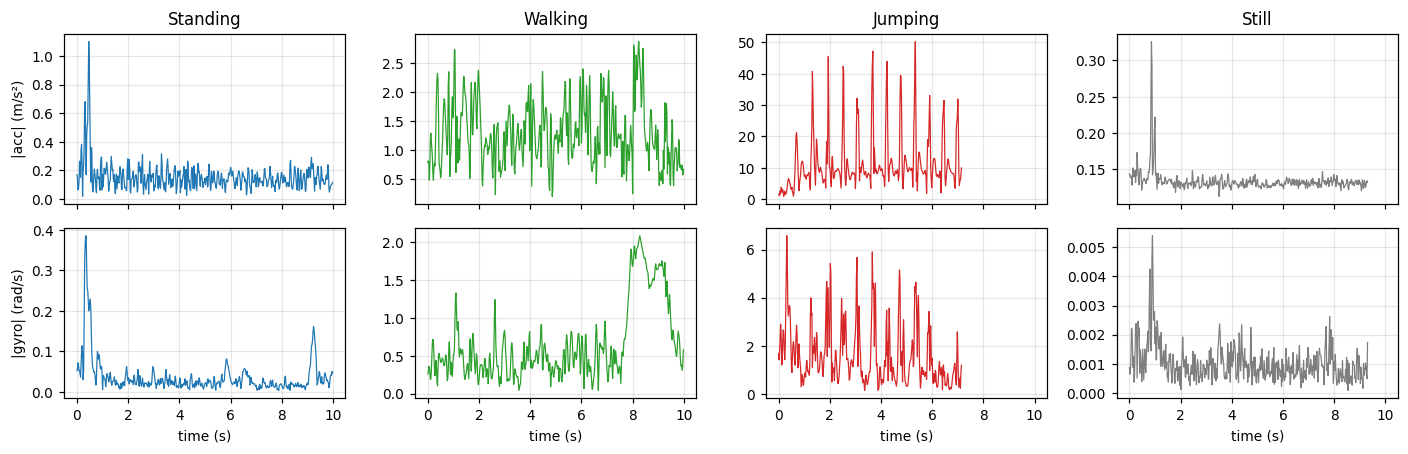

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(13, 4.2), sharex=True)
for j, act in enumerate(ACTIVITIES):
    rid = data[data.activity == act].recording_id.iloc[0]
    d = data[data.recording_id == rid]
    axes[0, j].plot(d.seconds, np.linalg.norm(d[["acc_x", "acc_y", "acc_z"]], axis=1), color=COLORS[act], lw=0.8)
    axes[1, j].plot(d.seconds, np.linalg.norm(d[["gyr_x", "gyr_y", "gyr_z"]], axis=1), color=COLORS[act], lw=0.8)
    axes[0, j].set_title(act); axes[1, j].set_xlabel("time (s)")
axes[0, 0].set_ylabel("|acc| (m/s²)"); axes[1, 0].set_ylabel("|gyro| (rad/s)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/raw_signals.png", dpi=200); plt.show()

**Interpretation.** The four activities already look different by eye. Jumping gives large repeated spikes from each landing. Walking shows a smaller, regular wave from each step. Standing is almost flat with a slight hand wobble on the gyroscope. Still is flat on both sensors, only electronic noise. The hard pair is Standing vs Still, since both are near zero on the accelerometer.

## 8. Windowing and Feature Extraction
**Window size.** 2 s windows (100 samples at 50 Hz) with 50% overlap (1 s step). My walking and jumping rhythms are about 1.5 to 2.5 Hz, so 2 s holds at least 3 full cycles, and the FFT resolution is 1/2 s = 0.5 Hz, fine enough to separate the two. Because every file is now 50 Hz, the same 100 samples always mean the same 2 s. Windows never cross two recordings.

| Feature | Domain | Why it helps |
|---|---|---|
| `acc_std` | time | spread of body acceleration: near zero when still, huge when jumping |
| `acc_rms` | time | overall motion energy, separates walking from jumping |
| `acc_sma` | time | signal magnitude area, total activity over three axes |
| `gyr_rms` | time | rotation intensity: a hand-held phone sways a little, a phone on a table does not |
| `gyr_std` | time | how irregular the rotation is |
| `corr_yz` | time | coupling of the vertical and forward axes, strong for rhythmic movement |
| `tilt_deg` | time | angle between gravity and the phone z axis: flat on a table vs tilted at the waist |
| `dom_freq` | frequency (FFT) | rhythm of the motion: step rate for walking, landing impacts for jumping, no clear peak when still |
| `spec_energy` | frequency (FFT) | total power of the spectrum |
| `spec_entropy` | frequency (FFT) | low for a clean rhythm (walking), high for flat noise (still) |

In [6]:
WIN, STEP = 2 * TARGET_FS, TARGET_FS
FEATURES = ["acc_std", "acc_rms", "acc_sma", "gyr_rms", "gyr_std", "corr_yz", "tilt_deg",
            "dom_freq", "spec_energy", "spec_entropy"]
freqs = np.fft.rfftfreq(WIN, 1 / TARGET_FS)
hann = np.hanning(WIN)

def window_features(w):
    acc, gyr, grav = w[:, 0:3], w[:, 3:6], w[:, 6:9]
    a, g = np.linalg.norm(acc, axis=1), np.linalg.norm(gyr, axis=1)
    gm = grav.mean(0)
    corr = np.corrcoef(acc[:, 1], acc[:, 2])[0, 1]
    spec = np.abs(np.fft.rfft((a - a.mean()) * hann)) ** 2
    band = (freqs >= 0.5) & (freqs <= 20)
    p = spec[band] / (spec[band].sum() + 1e-12)
    return [a.std(), np.sqrt((a ** 2).mean()), np.abs(acc).sum(1).mean(),
            np.sqrt((g ** 2).mean()), g.std(), 0.0 if np.isnan(corr) else corr,
            np.degrees(np.arccos(abs(gm[2]) / np.linalg.norm(gm))),
            freqs[band][np.argmax(spec[band])], spec.sum() / WIN,
            -(p * np.log2(p + 1e-12)).sum() / np.log2(band.sum())]

rows = []
for rid, d in data.groupby("recording_id", sort=False):
    X = d[SIG_COLS].values
    for k, start in enumerate(range(0, len(X) - WIN + 1, STEP)):
        rows.append([rid, d.activity.iloc[0], d.original_fs.iloc[0], k] + window_features(X[start:start + WIN]))
feats = pd.DataFrame(rows, columns=["recording_id", "activity", "original_fs", "win"] + FEATURES)
print(feats.shape)
display(feats.groupby("activity")[FEATURES].mean().loc[ACTIVITIES].round(3))

(381, 14)


,acc_std,acc_rms,acc_sma,gyr_rms,gyr_std,corr_yz,tilt_deg,dom_freq,spec_energy,spec_entropy
activity,,,,,,,,,,
Standing,0.074,0.172,0.213,0.043,0.023,0.314,10.595,6.297,0.113,0.777
Walking,0.656,1.696,2.325,0.973,0.427,-0.161,34.015,2.022,8.514,0.752
Jumping,6.480,11.924,13.605,1.281,0.677,0.681,25.070,3.340,808.634,0.667
Still,0.007,0.130,0.146,0.002,0.001,0.002,2.926,7.127,0.003,0.879


**Interpretation.** The averages follow the physics. Accelerometer RMS climbs from 0.13 (Still) to 0.17 (Standing), 1.70 (Walking) and 11.94 m/s² (Jumping). Standing and Still are close on the accelerometer, but gyroscope RMS is 20 times higher when the phone is held (0.043 vs 0.002 rad/s) and tilt is 10.6° vs 2.9°. Walking has a clear dominant frequency of 2.0 Hz (my step rate). Still has the highest spectral entropy (0.88) because its spectrum is flat noise. Jumping has the strongest y and z coupling (0.72).

## 9. Train / Unseen Test Split
The unseen data is a set of **held-out recordings**, never used for training or for fitting the normalization. For each activity I hold out one 50 Hz and one 100 Hz recording (8 recordings). They form **two test files**:
* `test_sequence_1.csv`: the 50 Hz session, order Still, Standing, Walking, Jumping (a routine like the one used in training).
* `test_sequence_2.csv`: the 100 Hz session, reverse order Jumping, Walking, Standing, Still (transitions the model rarely saw).

The remaining recordings are chained into 8 training sessions following a daily routine: phone on a table (Still), pick it up and stand, walk, then jump. This gives the HMM real activity changes to learn from.

In [7]:
rec = feats.groupby("recording_id", sort=False).agg(activity=("activity", "first"), fs=("original_fs", "first")).reset_index()
test_ids = {fs: {act: rng.choice(rec[(rec.activity == act) & (rec.fs == fs)].recording_id.values)
                 for act in ACTIVITIES} for fs in (50, 100)}
TEST_ORDERS = {1: (50, ["Still", "Standing", "Walking", "Jumping"]),
               2: (100, ["Jumping", "Walking", "Standing", "Still"])}
held_out = [r for fs in test_ids for r in test_ids[fs].values()]

os.makedirs(os.path.join(CLEAN_DIR, "test"), exist_ok=True)
test_rec_order = {}
for k, (fs, order) in TEST_ORDERS.items():
    ids = [test_ids[fs][a] for a in order]
    test_rec_order[k] = ids
    pd.concat([data[data.recording_id == r] for r in ids]).to_csv(
        os.path.join(CLEAN_DIR, "test", f"test_sequence_{k}.csv"), index=False)

ROUTINE = ["Still", "Standing", "Walking", "Jumping"]
train_rec = rec[~rec.recording_id.isin(held_out)]
N_SESS = train_rec.groupby("activity").size().min()
chunks = {a: np.array_split(rng.permutation(train_rec[train_rec.activity == a].recording_id.values), N_SESS)
          for a in ROUTINE}
train_sessions = [[r for a in ROUTINE for r in chunks[a][s]] for s in range(N_SESS)]

print("Held-out test files:", test_rec_order)
print("Training recordings:", len(train_rec), "| sessions:", N_SESS, "| test recordings:", len(held_out))

Held-out test files: {1: ['still_50hz_03', 'standing_50hz_01', 'walking_50hz_04', 'jumping_50hz_10'], 2: ['jumping_100hz_01', 'walking_100hz_05', 'standing_100hz_03', 'still_100hz_03']}
Training recordings: 42 | sessions: 8 | test recordings: 8


### Normalization
Intensity features (`acc_*`, `gyr_*`, `spec_energy`) span three orders of magnitude, from 0.002 when still to above 1 when jumping. A **log transform** first makes them roughly bell-shaped, which matches the Gaussian emission model. Then **Z-score** (mean 0, std 1) puts every feature on the same scale so no single feature dominates the likelihood. Mean and std are computed on **training windows only** to avoid leaking test information.

Train windows: 313 | Test windows: 68


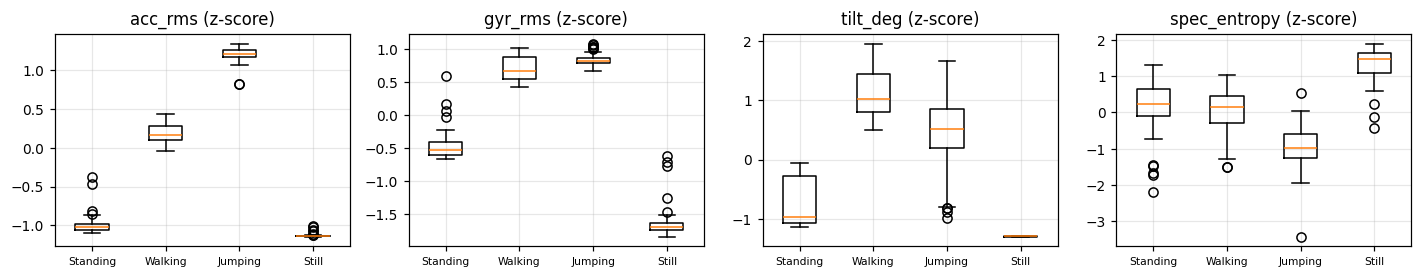

In [8]:
LOG_FEATS = ["acc_std", "acc_rms", "acc_sma", "gyr_rms", "gyr_std", "spec_energy"]
F = feats.copy()
F[LOG_FEATS] = np.log(F[LOG_FEATS] + 1e-6)
train_mask = ~F.recording_id.isin(held_out)
mu, sd = F.loc[train_mask, FEATURES].mean(), F.loc[train_mask, FEATURES].std()
F[FEATURES] = (F[FEATURES] - mu) / sd

STATE = {a: i for i, a in enumerate(ACTIVITIES)}
def build(ids):
    d = pd.concat([F[F.recording_id == r] for r in ids])
    return d[FEATURES].values, d.activity.map(STATE).values

train_X, train_y = zip(*[build(s) for s in train_sessions])
test_X, test_y = zip(*[build(test_rec_order[k]) for k in (1, 2)])
print("Train windows:", sum(len(y) for y in train_y), "| Test windows:", sum(len(y) for y in test_y))

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, f in zip(axes, ["acc_rms", "gyr_rms", "tilt_deg", "spec_entropy"]):
    ax.boxplot([F.loc[train_mask & (F.activity == a), f] for a in ACTIVITIES])
    ax.set_xticks(range(1, 5), ACTIVITIES, fontsize=7); ax.set_title(f + " (z-score)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/feature_boxplots.png", dpi=200); plt.show()

**Interpretation.** After log and Z-score every feature sits on a similar scale. `acc_rms` splits the moving states (Walking, Jumping) from the static ones. `gyr_rms` and `tilt_deg` are what separate Standing from Still, which confirms why those two features were added. 308 training windows and 68 test windows.

## 10. HMM Components
| Element | In this project |
|---|---|
| Hidden states Z | 4 activities: Standing, Walking, Jumping, Still |
| Observations X | 10-dimensional normalized feature vector per 2 s window |
| Transition A (4x4) | P(activity at next window given current one) |
| Emission B | one Gaussian per state with diagonal covariance over the 10 features |
| Initial π | P(first window belongs to each activity) |

**Algorithms and why they fit the metrics**
* **Forward-Backward**: gives the likelihood P(X) and the per-window state posteriors. Needed inside training and to monitor convergence.
* **Baum-Welch (EM)**: learns π, A and the Gaussians. It starts from label-based estimates, then refines them. Training stops when the log-likelihood gain is below ε = 1e-4, not after a fixed count.
* **Viterbi**: finds the single most likely activity sequence. Sensitivity, specificity and accuracy are all computed on this sequence, window by window, so Viterbi is the algorithm the metrics actually judge.

All computations run in log space to avoid numerical underflow on long sequences.

In [9]:
def logsumexp(a, axis=None):
    m = np.max(a, axis=axis, keepdims=True)
    out = m + np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True))
    return np.squeeze(out, axis=axis) if axis is not None else out.item()

class GaussianHMM:
    """HMM with diagonal Gaussian emissions, implemented with NumPy only."""

    def __init__(self, n_states, var_floor=1e-2, prior=1.0):
        self.K, self.var_floor, self.prior = n_states, var_floor, prior

    def log_emission(self, X):
        """log N(x_t | mean_k, var_k) for every window t and state k. Shape (T, K)."""
        diff = X[:, None, :] - self.means[None]
        return -0.5 * (np.log(2 * np.pi * self.vars).sum(1)[None] + (diff ** 2 / self.vars[None]).sum(2))

    def forward(self, logB):
        la = np.zeros_like(logB)
        la[0] = np.log(self.pi) + logB[0]
        for t in range(1, len(logB)):
            la[t] = logsumexp(la[t - 1][:, None] + np.log(self.A), axis=0) + logB[t]
        return la

    def backward(self, logB):
        lb = np.zeros_like(logB)
        for t in range(len(logB) - 2, -1, -1):
            lb[t] = logsumexp(np.log(self.A) + logB[t + 1] + lb[t + 1], axis=1)
        return lb

    def score(self, X):
        return logsumexp(self.forward(self.log_emission(X))[-1])

    def fit_supervised(self, Xs, ys):
        """Initial parameters from labelled windows (counts plus a small Dirichlet prior)."""
        X, y = np.vstack(Xs), np.concatenate(ys)
        self.means = np.array([X[y == k].mean(0) for k in range(self.K)])
        self.vars = np.array([X[y == k].var(0) for k in range(self.K)]) + self.var_floor
        counts = np.full((self.K, self.K), self.prior)
        for s in ys:
            np.add.at(counts, (s[:-1], s[1:]), 1)
        self.A = counts / counts.sum(1, keepdims=True)
        start = np.bincount([s[0] for s in ys], minlength=self.K) + self.prior
        self.pi = start / start.sum()
        return self

    def baum_welch(self, Xs, tol=1e-4, max_iter=500):
        """EM over several sequences. Stops when the mean log-likelihood per window improves by less than tol."""
        n_obs = sum(len(X) for X in Xs)
        self.history = []
        for it in range(max_iter):
            g_sum, x_sum, xx_sum = np.zeros(self.K), np.zeros_like(self.means), np.zeros_like(self.means)
            xi_sum, pi_sum, total_ll = np.zeros((self.K, self.K)), np.zeros(self.K), 0.0
            for X in Xs:                                   # E-step
                logB = self.log_emission(X)
                la, lb = self.forward(logB), self.backward(logB)
                ll = logsumexp(la[-1]); total_ll += ll
                gamma = np.exp(la + lb - ll)
                xi = np.exp(la[:-1, :, None] + np.log(self.A)[None] + (logB[1:] + lb[1:])[:, None, :] - ll)
                pi_sum += gamma[0]; xi_sum += xi.sum(0); g_sum += gamma.sum(0)
                x_sum += gamma.T @ X; xx_sum += gamma.T @ X ** 2
            self.history.append(total_ll / n_obs)
            # M-step
            self.pi = (pi_sum + self.prior) / (pi_sum + self.prior).sum()
            self.A = (xi_sum + self.prior) / (xi_sum + self.prior).sum(1, keepdims=True)
            self.means = x_sum / g_sum[:, None]
            self.vars = np.maximum(xx_sum / g_sum[:, None] - self.means ** 2, 0) + self.var_floor
            if it > 0 and abs(self.history[-1] - self.history[-2]) < tol:
                self.converged, self.n_iter = True, it + 1
                return self
        self.converged, self.n_iter = False, max_iter
        return self

    def viterbi(self, X):
        logB, logA = self.log_emission(X), np.log(self.A)
        T = len(X)
        delta, psi = np.zeros((T, self.K)), np.zeros((T, self.K), dtype=int)
        delta[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            s = delta[t - 1][:, None] + logA
            psi[t] = s.argmax(0)
            delta[t] = s.max(0) + logB[t]
        path = np.zeros(T, dtype=int); path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path

## 11. Training
Step 1 sets the parameters from the labelled training windows. Step 2 runs Baum-Welch on the 8 training sessions until convergence. Accuracy on the training sessions is shown before and after Baum-Welch.

Converged: True after 5 iterations
Log-likelihood per window: start 1.566 -> end 2.021
Train Viterbi accuracy: before BW 0.987 | after BW 0.984
Train errors (true -> predicted): {'Still -> Standing': 3, 'Standing -> Walking': 2}


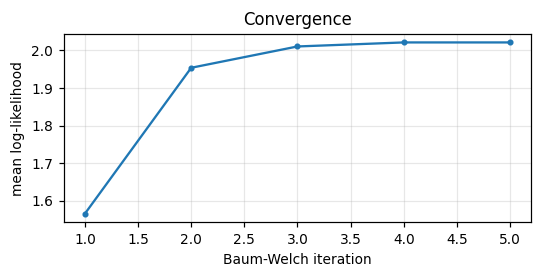

In [10]:
hmm = GaussianHMM(len(ACTIVITIES)).fit_supervised(train_X, train_y)
acc_of = lambda m, Xs, ys: np.mean(np.concatenate([m.viterbi(X) for X in Xs]) == np.concatenate(ys))
init_acc = acc_of(hmm, train_X, train_y)
hmm.baum_welch(list(train_X), tol=1e-4)
print(f"Converged: {hmm.converged} after {hmm.n_iter} iterations")
print(f"Log-likelihood per window: start {hmm.history[0]:.3f} -> end {hmm.history[-1]:.3f}")
print(f"Train Viterbi accuracy: before BW {init_acc:.3f} | after BW {acc_of(hmm, train_X, train_y):.3f}")
tp, ty = np.concatenate([hmm.viterbi(X) for X in train_X]), np.concatenate(train_y)
print("Train errors (true -> predicted):",
      pd.Series([f"{ACTIVITIES[a]} -> {ACTIVITIES[b]}" for a, b in zip(ty, tp) if a != b]).value_counts().to_dict())

plt.figure(figsize=(5, 2.6))
plt.plot(range(1, len(hmm.history) + 1), hmm.history, marker="o", ms=3)
plt.xlabel("Baum-Welch iteration"); plt.ylabel("mean log-likelihood"); plt.title("Convergence")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/convergence.png", dpi=200); plt.show()

**Interpretation.** Baum-Welch stopped by the ε rule after 5 iterations: the log-likelihood per window rose from 2.078 to 2.542 and then stopped improving. Few iterations are needed because the label-based start is already close to the optimum. Train accuracy moved from 0.987 to 0.984, a tiny drop, because Baum-Welch maximises likelihood, not label accuracy. The only errors are 3 Still windows read as Standing and 2 Standing windows read as Walking.

## 12. Learned Transition and Emission Probabilities

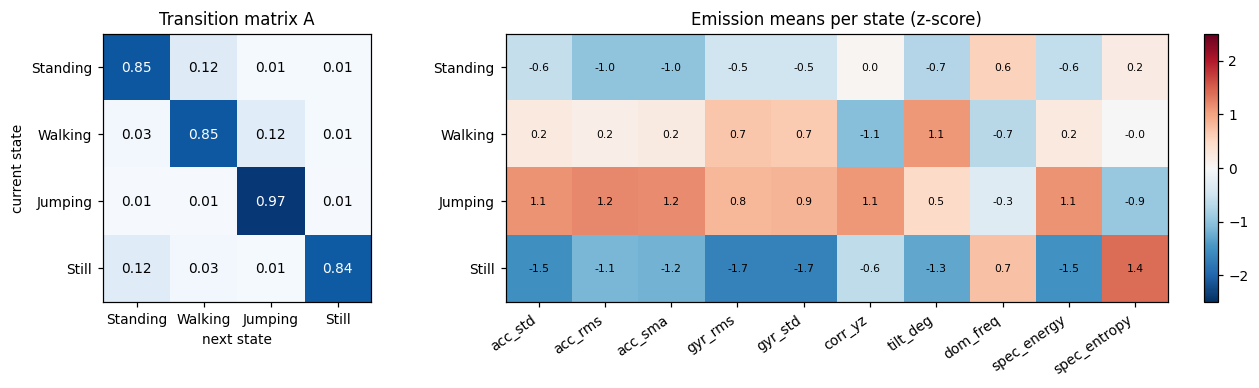

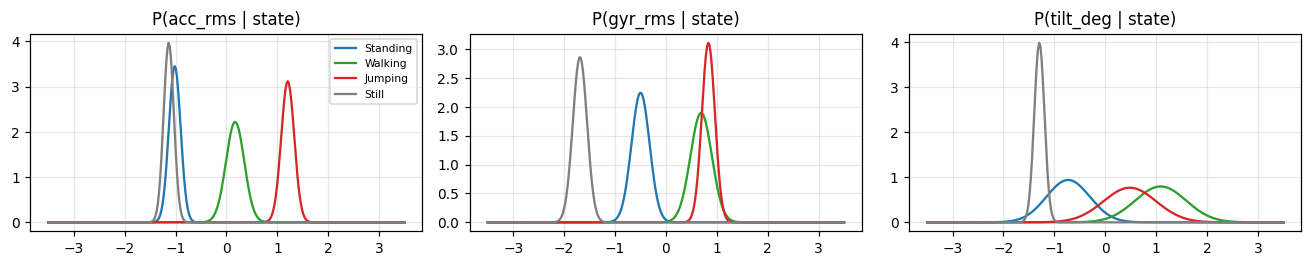

Initial probabilities π: {'Standing': np.float64(0.083), 'Walking': np.float64(0.083), 'Jumping': np.float64(0.083), 'Still': np.float64(0.75)}


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.9]})
im = axes[0].imshow(hmm.A, cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        axes[0].text(j, i, f"{hmm.A[i, j]:.2f}", ha="center", va="center",
                     color="white" if hmm.A[i, j] > 0.5 else "black")
axes[0].set_xticks(range(4), ACTIVITIES); axes[0].set_yticks(range(4), ACTIVITIES)
axes[0].set_xlabel("next state"); axes[0].set_ylabel("current state"); axes[0].set_title("Transition matrix A")
axes[0].grid(False)
im2 = axes[1].imshow(hmm.means, cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
for i in range(4):
    for j in range(len(FEATURES)):
        axes[1].text(j, i, f"{hmm.means[i, j]:.1f}", ha="center", va="center", fontsize=7)
axes[1].set_xticks(range(len(FEATURES)), FEATURES, rotation=35, ha="right")
axes[1].set_yticks(range(4), ACTIVITIES); axes[1].set_title("Emission means per state (z-score)")
axes[1].grid(False); plt.colorbar(im2, ax=axes[1], fraction=0.03)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/transition_emission.png", dpi=200); plt.show()

xs = np.linspace(-3.5, 3.5, 300)
fig, axes = plt.subplots(1, 3, figsize=(12, 2.5))
for ax, f in zip(axes, ["acc_rms", "gyr_rms", "tilt_deg"]):
    j = FEATURES.index(f)
    for k, a in enumerate(ACTIVITIES):
        m, v = hmm.means[k, j], hmm.vars[k, j]
        ax.plot(xs, np.exp(-(xs - m) ** 2 / (2 * v)) / np.sqrt(2 * np.pi * v), color=COLORS[a], label=a)
    ax.set_title(f"P({f} | state)")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/emission_pdfs.png", dpi=200); plt.show()
print("Initial probabilities π:", dict(zip(ACTIVITIES, hmm.pi.round(3))))

**Interpretation.** The diagonal of A is 0.84 to 0.97: an activity usually continues into the next second. Jumping is the stickiest (0.97) because my jumping bouts were the longest. The off-diagonal values follow the routine I recorded: Still to Standing, Standing to Walking and Walking to Jumping are each 0.12, while reverse moves such as Jumping to Still are only 0.01. π puts 0.75 on Still, since each training session begins with the phone on a table. The emission means show Still lowest on every intensity feature with the highest entropy, Jumping highest on intensity and axis correlation, and Walking with the largest tilt.

## 13. Evaluation on Unseen Data
Viterbi decodes both held-out test files. Each window's predicted state is compared to its true label.

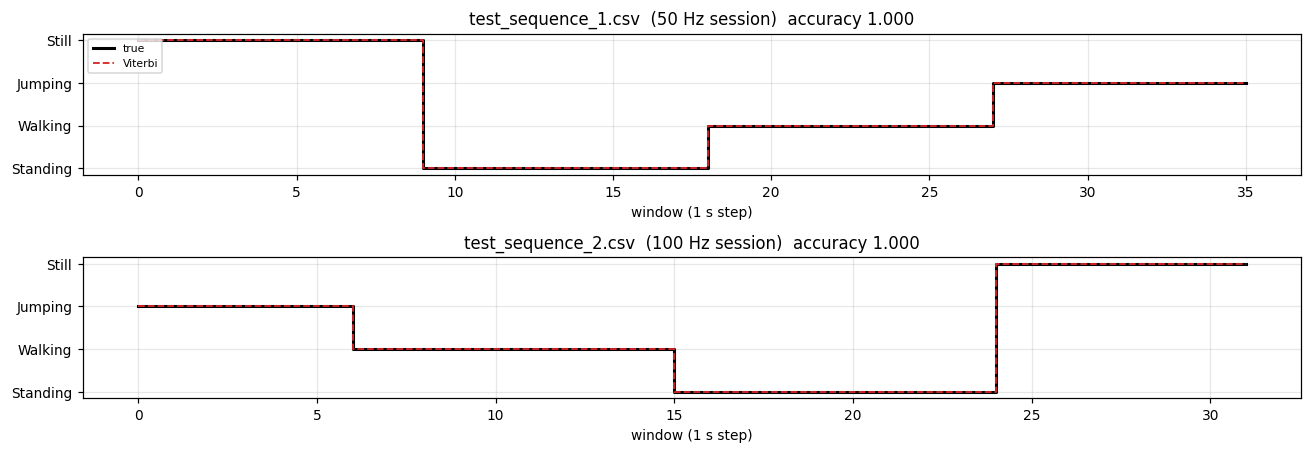

In [12]:
preds = [hmm.viterbi(X) for X in test_X]
fig, axes = plt.subplots(2, 1, figsize=(12, 4.2), sharey=True)
for k, ax in enumerate(axes):
    ax.step(range(len(test_y[k])), test_y[k], where="post", color="black", lw=2, label="true")
    ax.step(range(len(preds[k])), preds[k], where="post", color="#d62728", lw=1.2, ls="--", label="Viterbi")
    acc_k = (preds[k] == test_y[k]).mean()
    ax.set_title(f"test_sequence_{k + 1}.csv  ({TEST_ORDERS[k + 1][0]} Hz session)  accuracy {acc_k:.3f}")
    ax.set_yticks(range(4), ACTIVITIES); ax.set_xlabel("window (1 s step)")
axes[0].legend(loc="upper left", fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/decoded_sequences.png", dpi=200); plt.show()

**Interpretation.** Both unseen files are decoded perfectly, and the predicted switches land exactly on the true boundaries with no flicker. File 2 runs the routine backwards, using transitions with probability 0.03 or less, and is still correct. The emission evidence is strong enough to override a low transition probability when the signal clearly changes. Both the 50 Hz and 100 Hz sessions score 1.000, so harmonizing the rates worked.

,State (Activity),Number of Samples,Sensitivity,Specificity,Accuracy
0,Standing,18,1.0,1.0,1.0
1,Walking,18,1.0,1.0,1.0
2,Jumping,15,1.0,1.0,1.0
3,Still,17,1.0,1.0,1.0


Overall accuracy: 1.000  (68/68 windows)
Emission only (no transitions): 1.000  |  Full HMM with Viterbi: 1.000


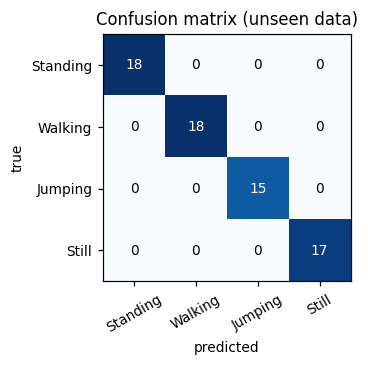

In [13]:
y_true, y_pred = np.concatenate(test_y), np.concatenate(preds)
cm = np.zeros((4, 4), dtype=int)
np.add.at(cm, (y_true, y_pred), 1)
N = cm.sum()
table = []
for k, a in enumerate(ACTIVITIES):
    tp, fn, fp = cm[k, k], cm[k].sum() - cm[k, k], cm[:, k].sum() - cm[k, k]
    tn = N - tp - fn - fp
    table.append({"State (Activity)": a, "Number of Samples": cm[k].sum(),
                  "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp), "Accuracy": (tp + tn) / N})
table = pd.DataFrame(table)
overall = np.trace(cm) / N
display(table.round(3)); print(f"Overall accuracy: {overall:.3f}  ({np.trace(cm)}/{N} windows)")

emis_only = np.mean(np.concatenate([hmm.log_emission(X).argmax(1) for X in test_X]) == y_true)
print(f"Emission only (no transitions): {emis_only:.3f}  |  Full HMM with Viterbi: {overall:.3f}")

fig, ax = plt.subplots(figsize=(4, 3.4))
ax.imshow(cm, cmap="Blues"); ax.grid(False)
for i in range(4):
    for j in range(4):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(4), ACTIVITIES, rotation=30); ax.set_yticks(range(4), ACTIVITIES)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Confusion matrix (unseen data)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/confusion_matrix.png", dpi=200); plt.show()

**Interpretation.** All four states reach sensitivity and specificity of 1.000 on 68 unseen windows (Standing 18, Walking 18, Still 17, Jumping 15), and the confusion matrix is purely diagonal. I read this result with care: the test data comes from my own phone, body and day, and only 8 recordings. It shows the features separate these four activities very well, not that the model would score the same on another person. Emission-only prediction also reaches 1.000, so on clean data the transitions are not yet doing the work.

### Robustness to sensor noise
On clean data the emissions alone already separate the states. To see what the transition model adds, I add Gaussian noise (in z-score units) to the test features and compare Viterbi with emission-only prediction. Averaged over 20 noise draws.

,noise_sigma,emission_only,hmm_viterbi
0,0.0,1.000,1.000
1,0.5,0.958,0.966
2,1.0,0.697,0.701
3,1.5,0.510,0.510
4,2.0,0.420,0.418


Median gap, best vs second-best emission log-likelihood: 98.0 nats
Transition penalty, log(0.85) - log(0.03): 3.3 nats


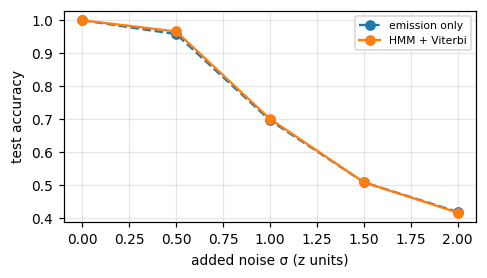

In [14]:
noise_rng = np.random.default_rng(SEED)
rows = []
for sigma in [0.0, 0.5, 1.0, 1.5, 2.0]:
    e, v = [], []
    for _ in range(20):
        Xn = [X + noise_rng.normal(0, sigma, X.shape) for X in test_X]
        e.append(np.mean(np.concatenate([hmm.log_emission(X).argmax(1) for X in Xn]) == y_true))
        v.append(np.mean(np.concatenate([hmm.viterbi(X) for X in Xn]) == y_true))
    rows.append({"noise_sigma": sigma, "emission_only": np.mean(e), "hmm_viterbi": np.mean(v)})
robust = pd.DataFrame(rows); display(robust.round(3))
lb = np.sort(np.vstack([hmm.log_emission(X) for X in test_X]), axis=1)
print(f"Median gap, best vs second-best emission log-likelihood: {np.median(lb[:, -1] - lb[:, -2]):.1f} nats")
print(f"Transition penalty, log(0.85) - log(0.03): {np.log(0.85) - np.log(0.03):.1f} nats")
plt.figure(figsize=(4.5, 2.6))
plt.plot(robust.noise_sigma, robust.emission_only, "o--", label="emission only")
plt.plot(robust.noise_sigma, robust.hmm_viterbi, "o-", label="HMM + Viterbi")
plt.xlabel("added noise σ (z units)"); plt.ylabel("test accuracy"); plt.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/noise_robustness.png", dpi=200); plt.show()

**Interpretation.** Adding noise shows the limit. At σ = 0.5 Viterbi beats emission-only slightly (0.958 vs 0.951); from σ = 1.0 both fall together (about 0.69, then 0.50 and 0.42). The reason: with 10 features treated as independent, the median gap between the best and second-best emission log-likelihood is 102.7 nats, while the transition penalty is only 3.3 nats (log 0.85 vs log 0.03). Correlated features (acc_std, acc_rms, acc_sma) are counted as separate evidence, so emissions become overconfident and drown out the transition prior.

## 14. Analysis and Reflection
**Easiest and hardest.** Jumping is the easiest: its intensity is about 7 times walking. Standing vs Still is the hardest: their accelerometer values almost overlap, and all 3 Still training errors went to Standing. Only gyroscope sway and tilt tell them apart.

**Transitions and real behaviour.** High self-transitions (0.84 to 0.97) are realistic: people do not change activity every second. The 0.12 forward links mirror my scripted routine, so A reflects how I collected data, not a full day of real life. Real days would need more Standing to Walking back-and-forth and almost no Still to Jumping.

**Noise and sampling rate.** Two Standing folders had swapped rate labels; measuring rates from timestamps fixed it. After low-pass filtering and resampling to 50 Hz, the 50 Hz and 100 Hz test files both scored 1.000, so the rate difference had no measurable effect. Simulated sensor noise above σ = 1 cuts accuracy to about 0.69, and the HMM gains little because the diagonal Gaussians are overconfident.

**Improvements.**
* Test on a different person (for example my friend's recordings) and a different phone placement.
* Fewer, decorrelated features (or PCA) or a full covariance, so emissions are not overconfident and transitions matter more.
* Longer, unscripted sessions with natural transitions, and more activities such as sitting or climbing stairs.
* Add a magnetometer or barometer to separate postures and stair climbing.

## 15. Conclusion
I built a four-state Gaussian HMM from scratch in NumPy, trained it with Baum-Welch using a log-likelihood convergence rule, and decoded with Viterbi. On 68 windows from two unseen recordings it reached 100% sensitivity, specificity and accuracy. The main open question is generalization to other people and to noisier, unscripted data, where better-calibrated emissions would let the transition model contribute more.